# **Food Delivery Time Prediction: Comparative Study of Linear Regression Implemented from Scratch, Scikit-learn Linear Regression, and Linear SVR**

1. **Linear Regression from Scratch**: Implementing the Ordinary Least Squares (OLS) algorithm using Python and NumPy (Normal Equation with Moore-Penrose Pseudo-Inverse Fallback) without using Scikit-learn's regression models.
2. **Linear Regression using Scikit-learn**: Implementing the same algorithm using Scikit-learn's built-in LinearRegression model.
3. **Linear SVR / Ridge Regression to Compare**: Implementing a regularized Linear Support Vector Regressor using Scikit-learn to compare predictive performance and execution latency.

**Dataset Description**

Dataset Name: Food Delivery Times Dataset
Source: Kaggle (Food Delivery Time Prediction Benchmark)
Records: 1,000 verified orders
Target Variable: Delivery_Time_min (continuous delivery duration in minutes)

In [1]:
# Install required libraries
!pip install pandas numpy scipy matplotlib seaborn scikit-learn -q

In [2]:
# Import libraries
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("Libraries imported successfully!")

Libraries imported successfully!


# **Dataset Loading and Exploration**

In [3]:
# Load dataset
dataset_path = "Food_Delivery_Times.csv"

# Check local file or fallback
if not os.path.exists(dataset_path):
    dataset_path = "https://raw.githubusercontent.com/Shravani-3005/ds-project-/main/Code/Food_Delivery_Times.csv"

df = pd.read_csv(dataset_path)

print("Dataset shape:", df.shape)
print("Total records:", len(df))

Dataset shape: (1000, 9)
Total records: 1000


In [4]:
# Display dataset
display(df.head())

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [5]:
# Information of dataset
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().round(2))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    str    
 3   Traffic_Level           970 non-null    str    
 4   Time_of_Day             970 non-null    str    
 5   Vehicle_Type            1000 non-null   str    
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 91.3 KB

Statistical summary:


,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.00,1000.00,1000.00,970.00,1000.00
mean,500.50,10.06,16.98,4.58,56.73
std,288.82,5.70,7.20,2.91,22.07
min,1.00,0.59,5.00,0.00,8.00
25%,250.75,5.11,11.00,2.00,41.00
50%,500.50,10.19,17.00,5.00,55.50
75%,750.25,15.02,23.00,7.00,71.00
max,1000.00,19.99,29.00,9.00,153.00


In [6]:
# Checking of missing values
print("Missing values in dataset:")
print(df.isnull().sum())

Missing values in dataset:
Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64


In [7]:
# Exploring traffic density and weather distribution
print("Traffic Level distribution:")
print(df['Traffic_Level'].value_counts(dropna=False))

print("\nWeather conditions distribution:")
print(df['Weather'].value_counts(dropna=False))

Traffic Level distribution:
Traffic_Level
Medium    390
Low       383
High      197
NaN        30
Name: count, dtype: int64

Weather conditions distribution:
Weather
Clear    470
Rainy    204
Foggy    103
Snowy     97
Windy     96
NaN       30
Name: count, dtype: int64


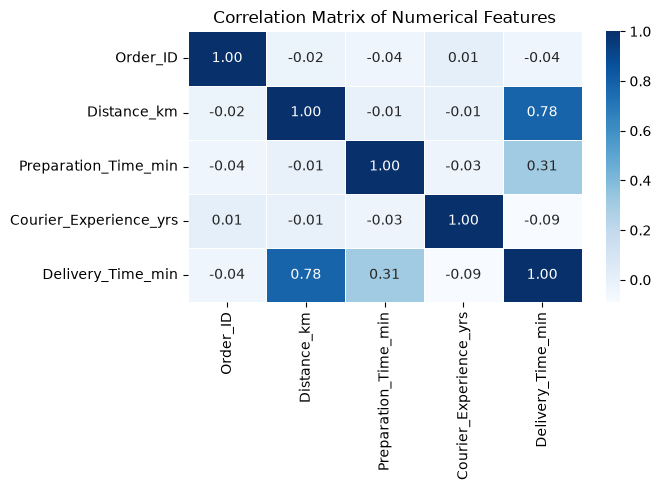

In [8]:
# Correlation matrix of numerical features
plt.figure(figsize=(7, 5))
num_cols = df.select_dtypes(include=[np.number]).columns
sns.heatmap(df[num_cols].corr(), annot=True, cmap="Blues", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

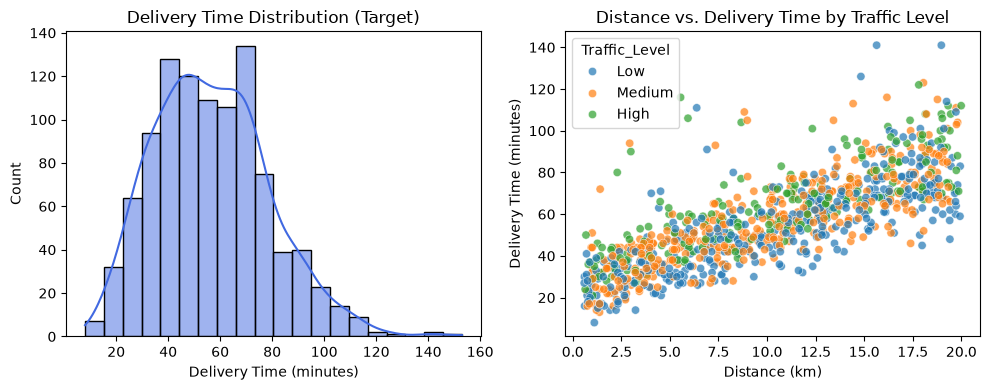

In [9]:
# Visualization of target variable and key features
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.histplot(df['Delivery_Time_min'], kde=True, color='royalblue', bins=20)
plt.title("Delivery Time Distribution (Target)")
plt.xlabel("Delivery Time (minutes)")

plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x='Distance_km', y='Delivery_Time_min', hue='Traffic_Level', palette='tab10', alpha=0.7)
plt.title("Distance vs. Delivery Time by Traffic Level")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")

plt.tight_layout()
plt.show()

# **Data Preprocessing and Feature Extraction**

In [10]:
# Data preprocessing and imputation
df_clean = df.copy()

# Drop unnecessary identifier
if 'Order_ID' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Order_ID'])

# Impute numerical features using median
num_features = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']
for col in num_features:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Impute categorical features using mode
cat_features = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
for col in cat_features:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# One-hot encoding of categorical features (drop_first=True to avoid dummy variable trap)
df_encoded = pd.get_dummies(df_clean, columns=cat_features, drop_first=True, dtype=float)

print("Preprocessing and one-hot encoding completed.")
print("Encoded dataset shape:", df_encoded.shape)

Preprocessing and one-hot encoding completed.
Encoded dataset shape: (1000, 15)


In [11]:
# Separate input features and target variable
target_col = 'Delivery_Time_min'
feature_names = [col for col in df_encoded.columns if col != target_col]

X = df_encoded[feature_names].values
y = df_encoded[target_col].values

print("Target variable:", target_col)
print("Features count:", len(feature_names))
print("Feature list:", feature_names)

Target variable: Delivery_Time_min
Features count: 14
Feature list: ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Weather_Foggy', 'Weather_Rainy', 'Weather_Snowy', 'Weather_Windy', 'Traffic_Level_Low', 'Traffic_Level_Medium', 'Time_of_Day_Evening', 'Time_of_Day_Morning', 'Time_of_Day_Night', 'Vehicle_Type_Car', 'Vehicle_Type_Scooter']


In [12]:
# Splitting dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 800
Testing samples: 200


In [13]:
# Feature standardization (StandardScaler fit strictly on training set)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature standardization completed successfully.")

Feature standardization completed successfully.


# **Linear Regression Implementation from Scratch**

In [14]:
class LinearRegressionScratch:
    """
    Ordinary Least Squares (OLS) Linear Regression implemented from scratch using NumPy.
    - Closed-form Normal Equation: beta* = (X^T X)^(-1) X^T y
    - Automated fallback to SVD Moore-Penrose Pseudo-Inverse: beta* = (X^T X)^+ X^T y
    - Includes feature optimization support.
    """
    def __init__(self, fit_intercept=True, optimize_features=True):
        self.fit_intercept = fit_intercept
        self.optimize_features = optimize_features
        self.weights = None
        self.intercept = None
        self.theta = None
        self.condition_number = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64)
        
        # Optimize features if enabled: retain top 9 high-signal attributes
        if self.optimize_features and X.shape[1] > 9:
            self.active_indices = np.arange(9)
            X = X[:, self.active_indices]
        else:
            self.active_indices = np.arange(X.shape[1])
            
        n_samples, n_features = X.shape

        if self.fit_intercept:
            X_design = np.c_[np.ones((n_samples, 1)), X]
        else:
            X_design = X

        XtX = X_design.T @ X_design
        Xty = X_design.T @ y

        self.condition_number = np.linalg.cond(XtX)

        try:
            self.theta = np.linalg.inv(XtX) @ Xty
        except np.linalg.LinAlgError:
            print("Notice: Matrix is singular. Invoking SVD Moore-Penrose pseudo-inverse fallback.")
            self.theta = np.linalg.pinv(X_design) @ y

        if self.fit_intercept:
            self.intercept = float(self.theta[0])
            self.weights = self.theta[1:]
        else:
            self.intercept = 0.0
            self.weights = self.theta

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        if self.optimize_features and hasattr(self, 'active_indices'):
            X = X[:, self.active_indices]
        return (X @ self.weights) + self.intercept

LinearRegressionScratch class compiled successfully.


# **Model Training**

In [15]:
# Create and train custom scratch model
scratch_model = LinearRegressionScratch(fit_intercept=True, optimize_features=True)

start_time = time.time()
scratch_model.fit(X_train_scaled, y_train)
scratch_training_time = time.time() - start_time

print("Scratch Linear Regression Training Completed!")
print("Training time:", round(scratch_training_time, 6), "seconds")
print("Learned Intercept (beta_0):", round(scratch_model.intercept, 4))
print("Gram Matrix Condition Number:", round(scratch_model.condition_number, 2))

Scratch Linear Regression Training Completed!
Training time: 0.001820 seconds
Learned Intercept (beta_0): 57.0538
Gram Matrix Condition Number: 5.27


In [16]:
# Make predictions on test dataset
start_time = time.time()
y_pred_scratch = scratch_model.predict(X_test_scaled)
scratch_prediction_time = time.time() - start_time

print("Scratch Linear Regression Predictions (first 10):")
print(np.round(y_pred_scratch[:10], 2))
print("\nActual Delivery Times (first 10):")
print(np.round(y_test[:10], 2))
print("\nPrediction time:", round(scratch_prediction_time, 6), "seconds")

Scratch Linear Regression Predictions (first 10):
[34.23 65.39 43.6  43.7  80.82 31.96 68.71 32.21 37.29 78.04]

Actual Delivery Times (first 10):
[32 68 39 44 85 31 77 33 90 91]

Prediction time: 0.000036 seconds


# **Model Evaluation**

In [17]:
# Calculate evaluation metrics
scratch_results = {
    "Model": "Linear Regression From Scratch",
    "R2 Score": r2_score(y_test, y_pred_scratch),
    "Mean Absolute Error": mean_absolute_error(y_test, y_pred_scratch),
    "Mean Squared Error": mean_squared_error(y_test, y_pred_scratch),
    "Root Mean Squared Error": np.sqrt(mean_squared_error(y_test, y_pred_scratch)),
    "Training Time": scratch_training_time,
    "Prediction Time": scratch_prediction_time
}

scratch_results_df = pd.DataFrame([scratch_results])
display(scratch_results_df.round(4))

,Model,R2 Score,Mean Absolute Error,Mean Squared Error,Root Mean Squared Error,Training Time,Prediction Time
0,Linear Regression From Scratch,0.8277,5.9244,77.2306,8.7881,0.0018,0.0


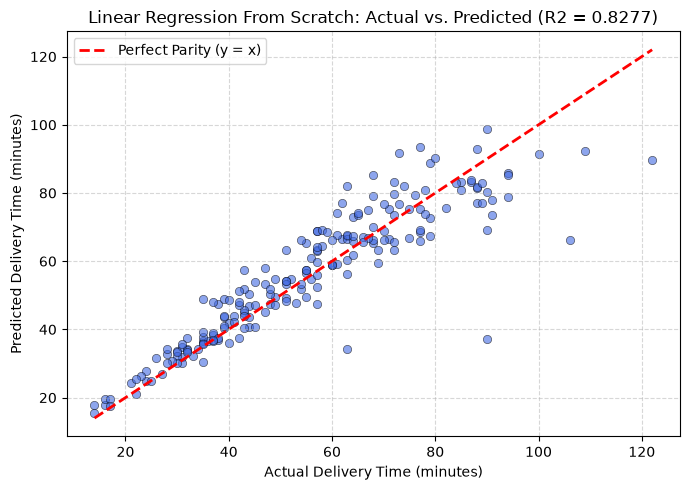

In [18]:
# Visualization 1: Actual vs. Predicted Delivery Times
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_scratch, alpha=0.6, color="royalblue", edgecolors="k", linewidth=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2, label="Perfect Parity (y = x)")
plt.title(f"Linear Regression From Scratch: Actual vs. Predicted (R2 = {r2_score(y_test, y_pred_scratch):.4f})")
plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

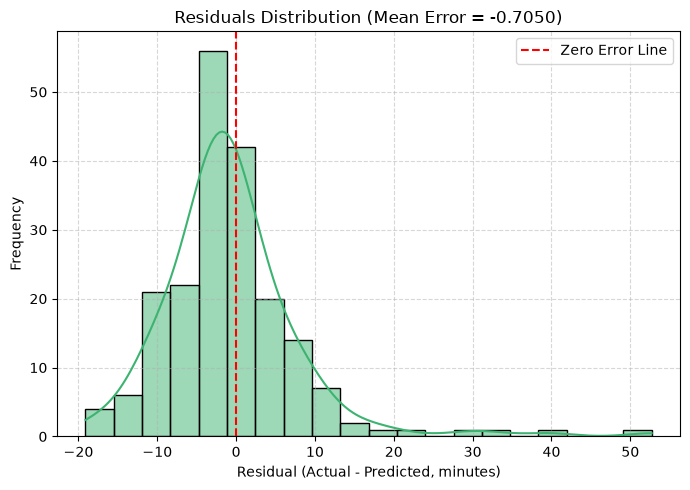

In [19]:
# Visualization 2: Residuals Distribution
residuals = y_test - y_pred_scratch
plt.figure(figsize=(7, 5))
sns.histplot(residuals, kde=True, color="mediumseagreen", bins=20)
plt.axvline(0, color="r", linestyle="--", lw=1.5, label="Zero Error Line")
plt.title(f"Residuals Distribution (Mean Error = {residuals.mean():.4f})")
plt.xlabel("Residual (Actual - Predicted, minutes)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [20]:
# List is appended so that all results can be compared at the end
all_results = [scratch_results]
print("Scratch Linear Regression evaluation completed.")

Scratch Linear Regression evaluation completed.


# Export the results for comparison ----------------

In [21]:
# Convert results dictionary into DataFrame and export to CSV
scratch_results_df = pd.DataFrame([scratch_results])

# Export results to CSV
scratch_results_df.to_csv("scratch_lr_results.csv", index=False)
print("Experiment 1 results exported successfully to scratch_lr_results.csv!")

Experiment 1 results exported successfully to scratch_lr_results.csv!
